In [25]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim

In [2]:
transform = transforms.Compose([ transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))  ])

In [4]:
train_data = torchvision.datasets.MNIST(root = "./data", download = True, train = True, transform = transform )

In [5]:
test_data = torchvision.datasets.MNIST(root = "./data", train = False, transform = transform)

In [8]:
train_loader = DataLoader(train_data, batch_size = 64, shuffle = True)
test_loader = DataLoader(test_data, batch_size = 64, shuffle = False)

0
4
1
9
2
1
3
1
4
3
5
3
6
1


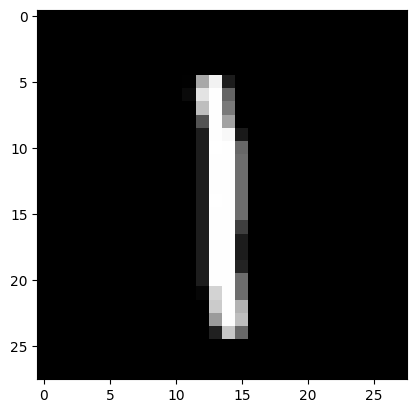

In [21]:
# for i in range(1,15):


#   img, label = train_data[i]
#   img = img.squeeze()

#   plt.imshow(img, cmap = "gray")
#   print(label)

In [23]:
class SimpleNN(nn.Module):
  def __init__(self):

    super(SimpleNN, self).__init__()
    self.flatten =  nn.Flatten()
    self.fc1 = nn.Linear(28*28, 128)
    self.relu = nn.ReLU()
    self.fc2 =  nn.Linear(128, 64)
    self.fc3 = nn.Linear(64, 10)

  def forward(self, x):

    x = self.flatten(x)
    x = self.fc1(x)
    x = self.relu(x)
    x  = self.fc2(x)
    x = self.fc3(x)

    return x



In [24]:
model = SimpleNN()
print(model)

SimpleNN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [27]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

In [29]:
# traning loop
train_loses = []
epochs = 5

for epoch in range(epochs):

  loss = 0
  for img, label in train_loader:
    optimizer.zero_grad()

    outputs = model(img)
    loss = loss_fn(img, label)
    loss.backward()
    optimizer.step()
    loss_total = loss_total + loss.item()

epoch_loss = loss_total / len(train_loader)
train_loses.append(epoch_loss)

print(f"Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss:.4f}")

RuntimeError: only batches of spatial targets supported (3D tensors) but got targets of dimension: 1

In [30]:
for img, label in train_loader:
    print("Images:", img.shape)
    print("Labels:", label.shape)

    outputs = model(img)
    print("Outputs:", outputs.shape)

    break

Images: torch.Size([64, 1, 28, 28])
Labels: torch.Size([64])
Outputs: torch.Size([64, 10])
